<a href="https://colab.research.google.com/github/fadeeva/nakedML/blob/master/MLnotes/005_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05/<br>Linear Regression

In [1]:
import numpy as np
import pandas as pd
import scipy as sp

from sklearn.linear_model import LinearRegression, Lasso, Ridge, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('ggplot')
np.random.seed(42)

## Quality Metrics

**MAE** - Mean Absolute Error
$$
MAE = \frac{1}{n}\sum^n_{i=1}{|y_i - y'_i|}
$$

**MAPE** - Mean Absolute Percentage Error
$$
MAPE = \frac{1}{n}\sum^n_{i=1}{\frac{|y_i - y'_i|}{|y_i|}} \cdot 100\%
$$

In [2]:
mae = lambda Y, Yp: 1/len(Y) * np.sum(np.abs(Y - Yp))
mape = lambda Y, Yp: 1/len(Y) * np.sum(np.abs(Y - Yp) / np.abs(Y)) * 100

## Defenition

A regression model is called linear if the predicted value of the target feature Y is computed as a sum of the known features $x_1, x_2, x_3, ... , x_n$ taken with certain weights. The goal is to determine the weights.

$$
y' = w_1x_1 + w_2x_2 + ... + w_mx_m + w_0
$$


>**Note**<br>
>A regression model does NOT have to fit the training data exactly.

<br>

**Weight estimation principle.** The objective is to minimize the deviation between the predicted values and the true values of Y.

>**Note**<br>
>Linear regression is sensitive to outliers — they should be removed beforehand.

$$
|y' - y| = |w_1x_1 + w_0 - y|
$$

$|y' - y|$ — exactly what we need to minimize.

or same:

$$
L(w_1, w_0) = |w_1x_1 + w_0 - y_1| + |w_2x_2 + w_0 - y_2| + |w_3x_3 + w_0 - y_3| + |w_4x_4 + w_0 - y_4|
$$

<br>

Since the absolute value function is not differentiable, the sum of squared deviations is minimized instead:

$$
L(w_1, w_0) = (w_1x_1 + w_0 - y_1)^2 + (w_2x_2 + w_0 - y_2)^2 + (w_3x_3 + w_0 - y_3)^2 + (w_4x_4 + w_0 - y_4)^2
$$

<br>

Next, we compute the partial derivatives and set them equal to zero and calculate values of $w_1$ and $w_0$:

$$
\begin{cases}
\frac{\partial L}{\partial w_1} = 0 \\ \frac{\partial L}{\partial w_0} = 0
\end{cases}
$$

<br>

### Sample

|   | x | y |
|---|---|---|
| A |-1 | 1 |
| B | 0 | 0 |
| C | 1 | 1 |
| D | 2 | 4 |

$$
L(w_1, w_0) = (w_1\cdot(-1) + w_0 - 1)^2 + (w_2\cdot0 + w_0 - 0)^2 + (w_3\cdot1 + w_0 - 1)^2 + (w_4\cdot2 + w_0 - 4)^2
$$

$$
L(w_1, w_0) = 6w_1^2 + 4w_0^2 + 4w_1w_0 - 16w_1 - 12w_0 + 18
$$

$$
\begin{cases}
\frac{\partial L}{\partial w_1} = 12w_1 + 4w_0 - 16 = 0 \\ \frac{\partial L}{\partial w_0} = 4w_1 + 8w_0 - 12 = 0
\end{cases}
$$

$$
w_1 = 1, w_0 = 1, y' = x + 1
$$

<br>

>**Problems**  when constructing systems of linear equations:
> 1. No solution
> 2. More than one solution
> 3. Points 1 and 2 arise when the determinant of the equations equals 0. However, a determinant close to 0 is also problematic.

*These problems arise when there is a linear dependency or strong correlation (multicollinearity) between the non-target features.*

>**Solutions** what we need for good regression model:
> 1. Feature selection. Remove non-target features that are linearly dependent on each other.
> 2. Regression coefficients can be minimized via *regularization*.


In [3]:
N = 100
noise = 5.0

X = np.random.uniform(0, 10, size=N)

w_true = 2.5   # slope
b_true = 1.0   # intercept

y = w_true * X + b_true + np.random.normal(0, noise, size=N)

X_2d = X.reshape(-1, 1)

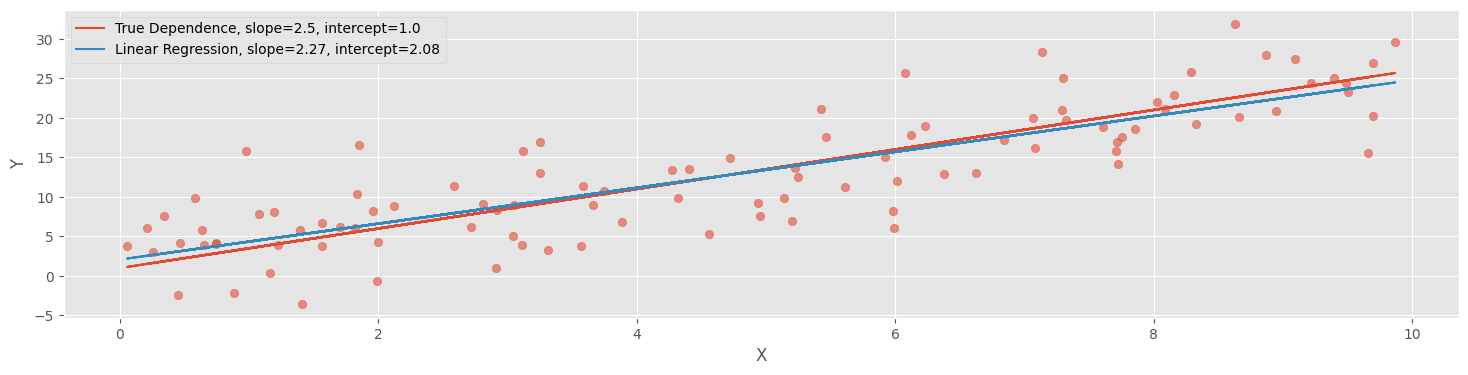

In [4]:
simple_linear = LinearRegression()
simple_linear.fit(X_2d, y)

w_lr = simple_linear.coef_[0]
b_lr = simple_linear.intercept_

plt.figure(figsize=(18, 4))
plt.scatter(X, y, alpha=0.6)
plt.plot(X, w_true * X + b_true, label=f'True Dependence, slope={w_true}, intercept={b_true}')
plt.plot(X, w_lr * X + b_lr, label=f'Linear Regression, slope={w_lr:.2f}, intercept={b_lr:.2f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

## Regularization

Main idea:

$$
R = L(w_1, w_2, ..., w_m, w_0) + C(w_1^2 + w_2^2 + ... + w_m^2 + w_0^2)
$$
where $C$ is a given constant.


### Sample

let $C = 1$ =>
$$R = L(w_1, w_2, ..., w_m, w_0) + w_1^2 + w_2^2 + ... + w_m^2 + w_0^2$$

|   | $x_1$ | $x_2$ | Y |
|---|-------|-------|---|
| A |-1     | -1    | 1 |
| B | 0     | 0     | 0 |
| C | 1     | 1     | 1 |
| D | 2     | 2     | 4 |

$$
\begin{cases}
\frac{\partial R}{\partial w_1} = (12w_1 + 12w_2 + 4w_0 - 16) + 2w_1 = 16, w_1 = 1.36
\\
\frac{\partial R}{\partial w_2} = (12w_1 + 12w_2 + 4w_0 - 16) + 2w_2 = 16, w_2 = -0.25
\\
\frac{\partial R}{\partial w_0} = (4w_1 + 4w_2 + 8w_0 - 12) + 2w_0 = 12, w_0 = 0.75
\end{cases}
$$


>**How to choose $C$:**
> 1. Choose as many different values of C as possible.
> 2. For each value, train a regression model and evaluate its performance on the test set.
> 3. Select the value of C that belongs to the model with the best performance.


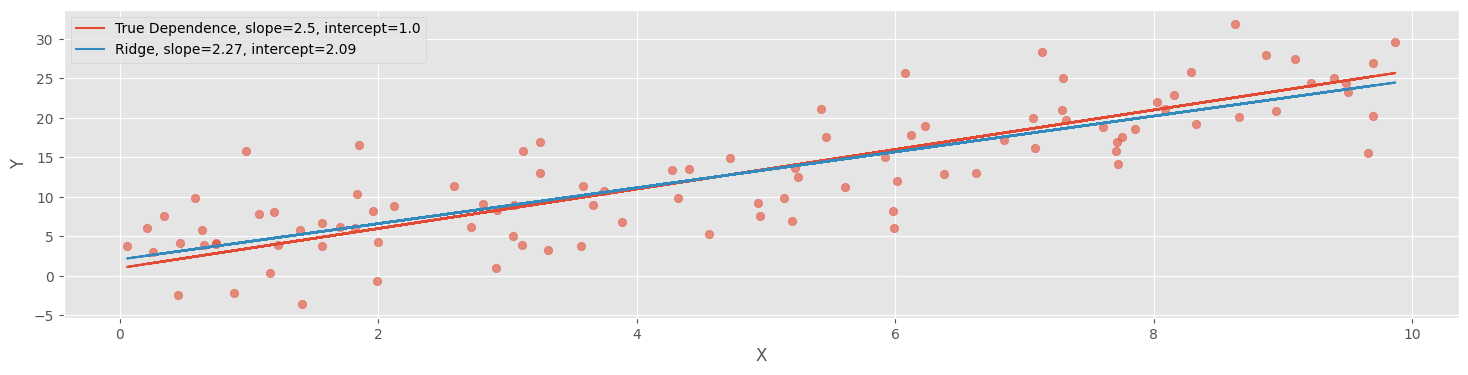

In [5]:
model = Ridge()
model.fit(X_2d, y)

w_rd = model.coef_[0]
b_rd = model.intercept_

plt.figure(figsize=(18, 4))
plt.scatter(X, y, alpha=0.6)
plt.plot(X, w_true * X + b_true, label=f'True Dependence, slope={w_true}, intercept={b_true}')
plt.plot(X, w_rd * X + b_rd, label=f'Ridge, slope={w_rd:.2f}, intercept={b_rd:.2f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

Text(0.5, 1.0, 'Checking alpha within a range')

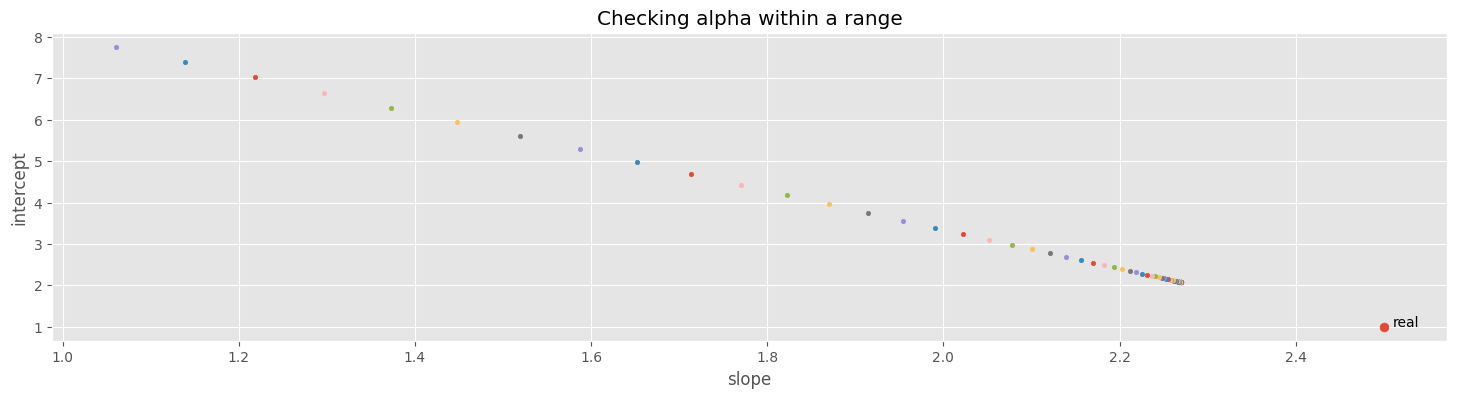

In [6]:
plt.figure(figsize=(18, 4))
plt.scatter(w_true, b_true, s=40)
plt.annotate('real', xy=np.array([w_true, b_true]), xytext=np.array([w_true, b_true])+.01)

for alpha in np.logspace(-3, 3, 100):
    model = Ridge(alpha=alpha)
    model.fit(X_2d, y)

    w_rd = model.coef_[0]
    b_rd = model.intercept_

    plt.scatter(w_rd, b_rd, s=10)

plt.xlabel('slope')
plt.ylabel('intercept')
plt.title('Checking alpha within a range')

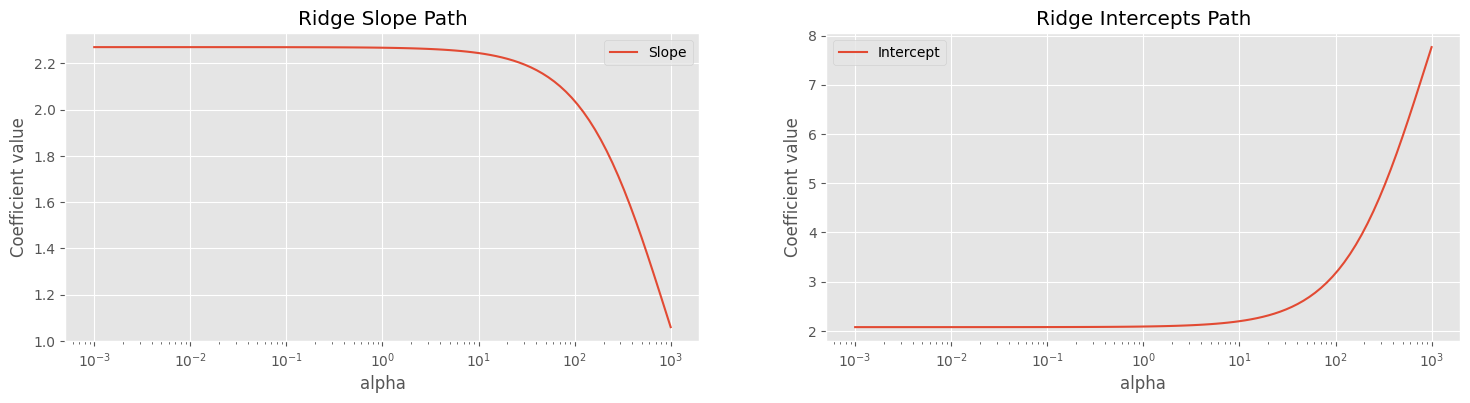

In [7]:
alphas = np.logspace(-3, 3, 100)
slopes, intercepts = [], []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_2d, y)
    slopes.append(model.coef_[0])
    intercepts.append(model.intercept_)

fig, axs = plt.subplots(1, 2, figsize=(18, 4))

axs[0].plot(alphas, slopes, label='Slope')
axs[0].set_title('Ridge Slope Path')
axs[0].set_xscale('log')
axs[0].set_xlabel('alpha')
axs[0].set_ylabel('Coefficient value')
axs[0].legend()

axs[1].plot(alphas, intercepts, label='Intercept')
axs[1].set_title('Ridge Intercepts Path')
axs[1].set_xscale('log')
axs[1].set_xlabel('alpha')
axs[1].set_ylabel('Coefficient value')
axs[1].legend()


In [8]:
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5)
ridge_cv.fit(X_2d, y)
print(f'Best alpha for Ridge: {ridge_cv.alpha_}')
print(f'slope = {ridge_cv.coef_[0]:.2f}')
print(f'intercept = {ridge_cv.intercept_:.2f}')

Best alpha for Ridge: 46.41588833612782
slope = 2.16
intercept = 2.61


### Lasso

$$
R = L(w_1, w_2, ..., w_m, w_0) + C(|w_1| + |w_2| + ... + |w_m| + |w_0|)
$$

Here, $w$ can only be found using optimization methods.

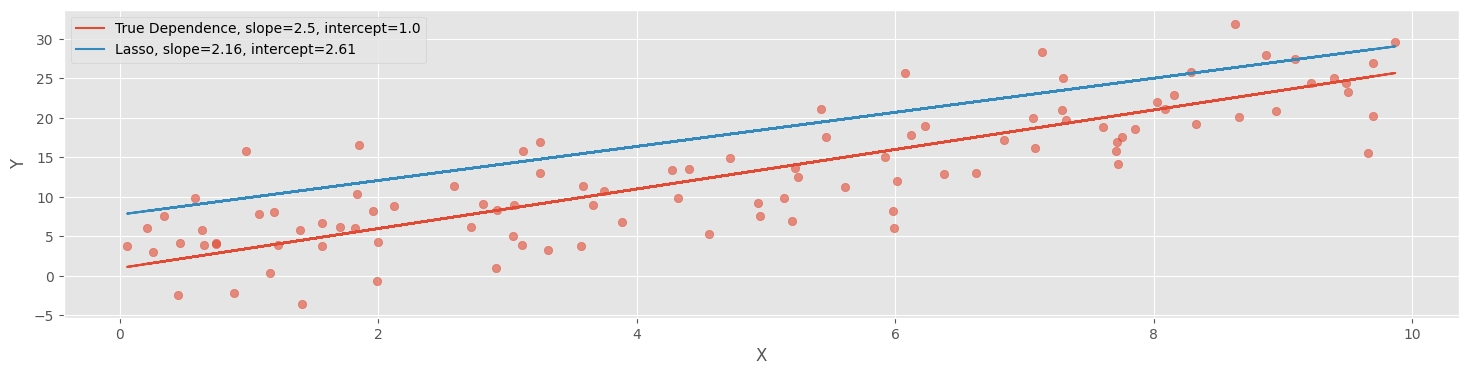

In [9]:
model = Lasso()
model.fit(X_2d, y)

w_ls = model.coef_[0]
b_ls = model.intercept_

plt.figure(figsize=(18, 4))
plt.scatter(X, y, alpha=0.6)
plt.plot(X, w_true * X + b_true, label=f'True Dependence, slope={w_true}, intercept={b_true}')
plt.plot(X, w_ls * X + b_rd, label=f'Lasso, slope={w_ls:.2f}, intercept={b_ls:.2f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

Text(0.5, 1.0, 'Checking alpha within a range')

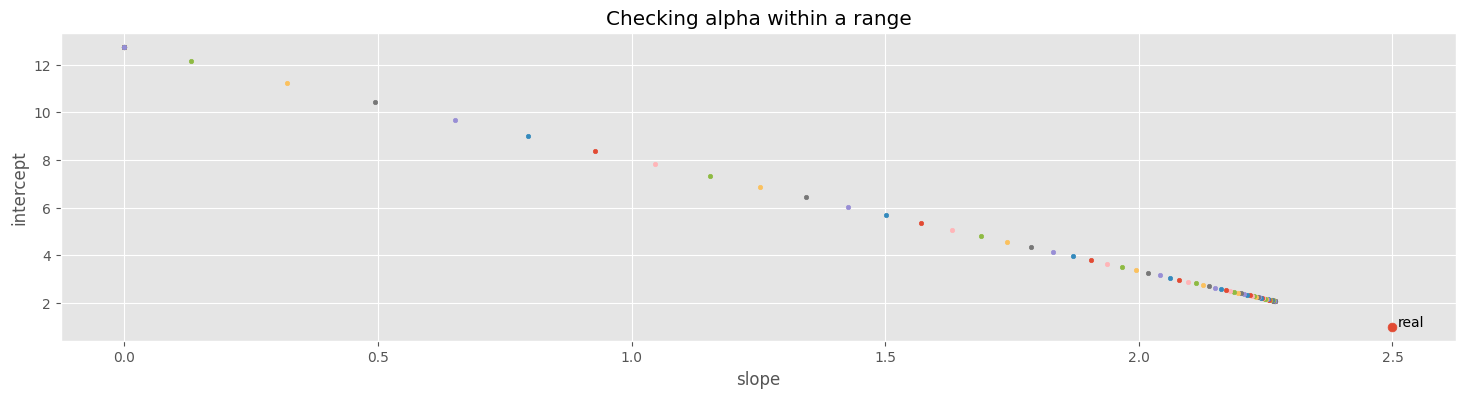

In [10]:
plt.figure(figsize=(18, 4))
plt.scatter(w_true, b_true, s=40)
plt.annotate('real', xy=np.array([w_true, b_true]), xytext=np.array([w_true, b_true])+.01)

for alpha in np.logspace(-2, 2, 100):
    model = Lasso(alpha=alpha)
    model.fit(X_2d, y)

    w_rd = model.coef_[0]
    b_rd = model.intercept_

    plt.scatter(w_rd, b_rd, s=10)

plt.xlabel('slope')
plt.ylabel('intercept')
plt.title('Checking alpha within a range')

In [11]:
lasso_cv = LassoCV(alphas=np.logspace(-3, 3, 100), cv=5)
lasso_cv.fit(X_2d, y)
print(f'Best alpha for Ridge: {lasso_cv.alpha_}')
print(f'slope = {lasso_cv.coef_[0]:.2f}')
print(f'intercept = {lasso_cv.intercept_:.2f}')

Best alpha for Ridge: 0.021544346900318846
slope = 2.27
intercept = 2.09


## Comparison of Metrics

In [12]:
models = {'Linear': simple_linear, 'Ridge': ridge_cv, 'Lasso': lasso_cv}
results = {}

for name, m in models.items():
    y_pred = m.predict(X_2d)
    results[name] = {
        'MAE': mean_absolute_error(y, y_pred),
        'MSE' : mean_squared_error(y, y_pred),
        'R2': r2_score(y, y_pred)
    }

pd.DataFrame(results).T

,MAE,MSE,R2
Linear,3.505213,20.164614,0.691277
Ridge,3.484569,20.278905,0.689527
Lasso,3.504419,20.164667,0.691276


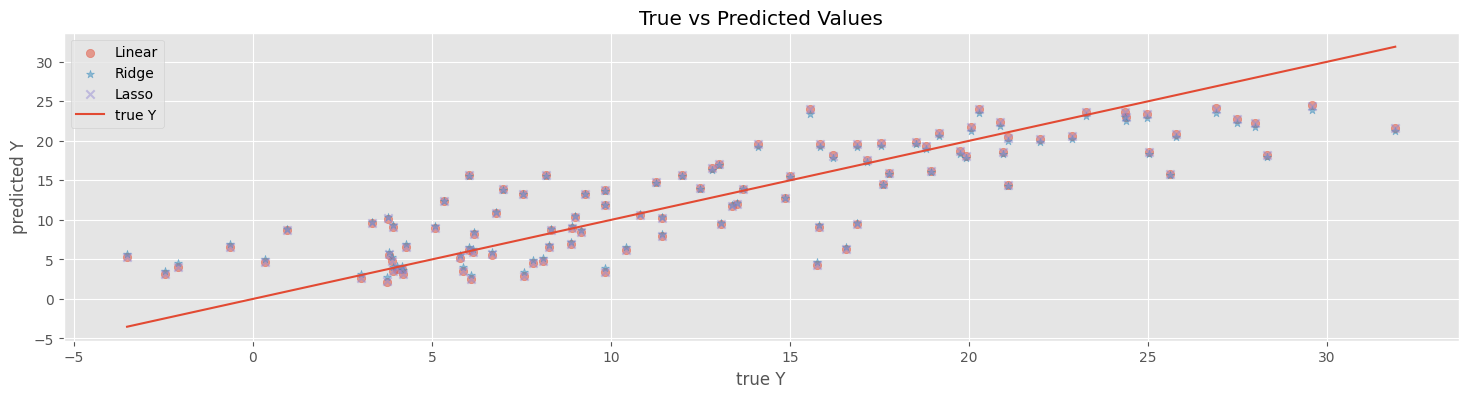

In [13]:
plt.figure(figsize=(18, 4))

for (name, model), m in zip(models.items(), ['o', '*', 'x']):
    plt.scatter(y, model.predict(X_2d), alpha=0.5, marker=m, label=name)

plt.plot([y.min(), y.max()], [y.min(), y.max()], label='true Y')
plt.xlabel('true Y')
plt.ylabel('predicted Y')
plt.title('True vs Predicted Values')
plt.legend()


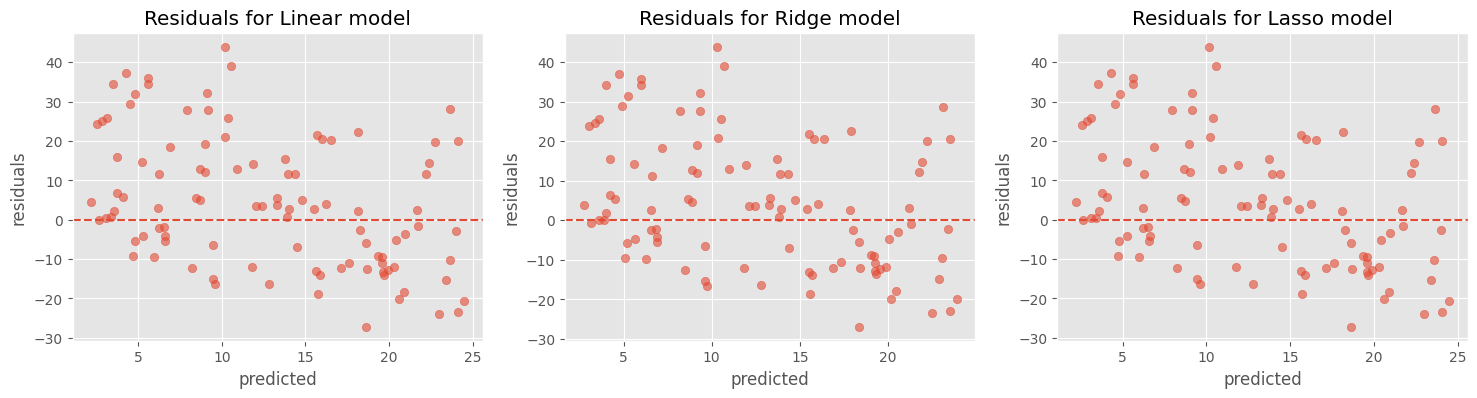

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for i, (name, model) in enumerate(models.items()):
    residuals = y - model.predict(X_2d)
    axs[i].scatter(model.predict(X_2d), residuals, alpha=0.6)
    axs[i].axhline(y=0, linestyle='--')
    axs[i].set_xlabel('predicted')
    axs[i].set_ylabel('residuals')
    axs[i].set_title(f'Residuals for {name} model')


Text(0.5, 0.98, 'Distribution of True vs Predicted Values')

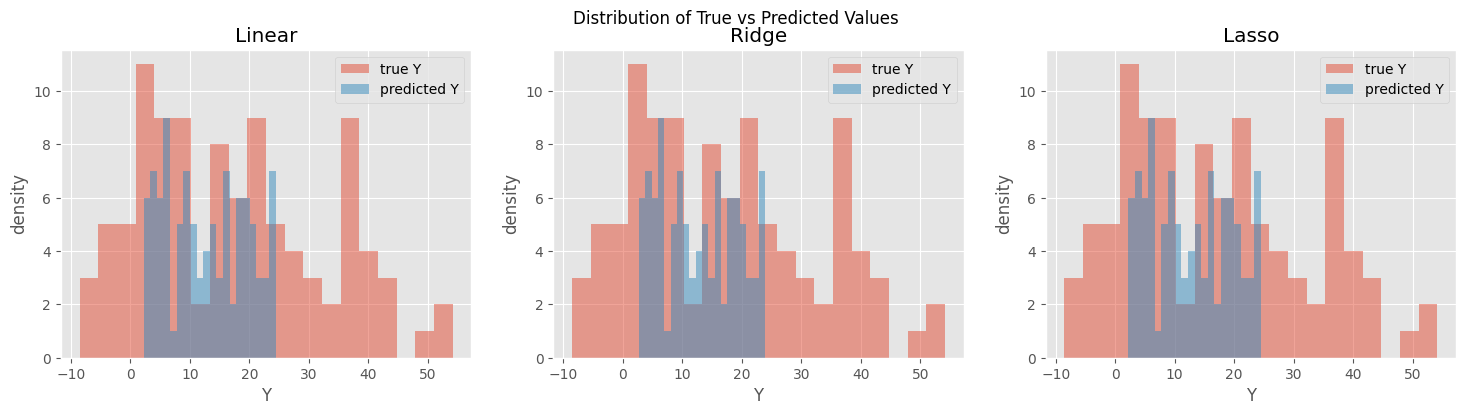

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for i, (name, model) in enumerate(models.items()):
    axs[i].hist(y, bins=20, alpha=0.5, label='true Y')
    axs[i].hist(model.predict(X_2d), bins=20, alpha=0.5, label='predicted Y')
    axs[i].set_xlabel('Y')
    axs[i].set_ylabel('density')
    axs[i].set_title(f'{name}')
    axs[i].legend()

fig.suptitle('Distribution of True vs Predicted Values')

## Polynomial regression

In general, if one wants to find the dependence of the target feature in the form of a polynomial of degree k, new columns must be added to the table containing all possible products of non-target variables of degree at most k.

|   | $x$ | $z$ |$xx$| $zz$ | $xz$ | Y |
|---|-----|-----|----|------|------|---|
| A | 1   |  3  | 1  |   9  |  3   |100|
| B | 1   |  4  | 4  |  16  |  8   |200|

> **Note**<br>
> Increasing the degree of the polynomial does not necessarily improve prediction accuracy.

In [14]:
def show_result(predict_w:set, real_w:set):
    ws, b = predict_w
    wrs, br = real_w

    print(*[f'{predict:.2f}({real})' for predict, real in zip(ws, wrs)], sep=', ')
    print(f'{b:.2f}({br})')


In [15]:
N = 100
noise = 5.0

X = np.random.uniform(0, 10, size=N)
Z = np.random.uniform(0, 10, size=N)

wx_true = 2.5
wz_true = -1.8
wx2_true = 0.3
wz2_true = 0.2
wxz_true = -0.1
b_true = 1.0

true_coef = [wx_true, wz_true, wx2_true, wz2_true, wxz_true]

y = (wx_true * X
     + wz_true * Z
     + wx2_true * X**2
     + wz2_true * Z**2
     + wxz_true * X * Z
     + b_true
     + np.random.normal(0, noise, size=N))

model = LinearRegression()
model.fit(np.column_stack([X, Z, X**2, Z**2, X*Z]), y)

show_result((model.coef_, model.intercept_), (true_coef, b_true))

2.13(2.5), -2.07(-1.8), 0.28(0.3), 0.17(0.2), 0.01(-0.1)
3.01(1.0)


In [16]:
# same but w/ sklearn

X_input = np.column_stack([X, Z])

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_input)

model = LinearRegression()
model.fit(X_poly, y)

show_result((model.coef_, model.intercept_), (true_coef, b_true))

2.13(2.5), -2.07(-1.8), 0.28(0.3), 0.01(0.2), 0.17(-0.1)
3.01(1.0)


In [17]:
model = Ridge()
model.fit(X_poly, y)

print('Ridge:')
show_result((model.coef_, model.intercept_), (true_coef, b_true))

Ridge:
2.09(2.5), -2.03(-1.8), 0.29(0.3), 0.01(0.2), 0.17(-0.1)
3.00(1.0)


In [18]:
model = Lasso()
model.fit(X_poly, y)

print('Lasso:')
show_result((model.coef_, model.intercept_), (true_coef, b_true))

Lasso:
0.54(2.5), -0.15(-1.8), 0.43(0.3), 0.00(0.2), -0.00(-0.1)
2.27(1.0)
